# TeaLeafDiseaseBD — field-condition external test (Reviewer 1.1, 1.2, 2.1, 2.2)

Dataset: Chowdhury & Arman, *Tea Leaf Disease Image Dataset for Automated Classification of Tea Garden
Diseases*, Mendeley Data, doi:10.17632/3x42rbj8yv.1 (CC BY 4.0). 2,500 field photographs, natural daylight,
four gardens in Chunarughat, Habiganj, April–June 2025; classes Blight, Healthy Leaf, Red Rust, Helopeltis.

The 70-label probe and the exported student are tested **unchanged**; thresholds are fixed at 95%
sensitivity on the TeaLeafDiseaseBD test split before any field image is scored. Two crop conditions:
**whole frame** (no segmentation) and **SAM centre-leaf crop** (Segment Anything ViT-B, prompted with the image
centre). Analyses: binary zero-shot, 4-class zero-shot (Blight = Brown + Gray Blight), per-class detection,
label-free threshold, few-label recalibration with near-duplicates held out, leakage check.

Checks that stop or warn: preprocessing reproduces cached features (Cell 4); probes reproduce published AUCs
(Cell 5); ONNX checksum (Cell 13); contact sheets (Cell 9) — **look at them**; within-set near-duplicates (Cell 14).
GPU runtime; ~30–40 min (SAM dominates).

In [1]:
# CELL 0 — CONFIG (edit paths only)
DRIVE = '/content/drive/MyDrive'
TEA_ROOT   = f'{DRIVE}/Tea Leaf Dataset'
RES        = f'{DRIVE}/TeaLeaf_DINOv2_Study/results_revision_v1'
FEATS      = f'{RES}/features_dinov1_crop.npz'
SPLIT      = f'{RES}/_split.json'
EJSON      = f'{RES}/E_distillation_5rep.json'
DEPLOY     = f'{RES}/deploy'
ONNX_PATH  = f'{DEPLOY}/tea_screener.onnx'
ONNX_REPORT= f'{DEPLOY}/export_report.json'
ONNX_ID_SCORES = f'{DEPLOY}/tea_screener_test_scores.npy'
FIELD_ZIP_OR_DIR = f'{DRIVE}/Tea Field Dataset'   # folder holding the Mendeley download (zip or extracted)
OUT        = f'{RES}/field_test'
SEED, N_SHOT, N_REP, PAD, IMG, JPEG_Q = 42, 10, 5, 0.06, 224, 95
HEALTHY_IDX = 3
TARGET_SENS = 0.95
DUP = 0.95
RECAL_DRAWS = 40
SAM_MAX_SIDE = 1024        # images are downscaled to this before SAM (they are up to 3024 px)
SAM_AREA = (0.03, 0.90)    # accept a SAM mask only if it covers 3–90% of the frame


In [2]:
# CELL 1 — setup
from google.colab import drive; drive.mount('/content/drive')
!pip -q install onnx onnxruntime pyyaml git+https://github.com/facebookresearch/segment-anything.git
!wget -q -nc --no-check-certificate https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -P /content/
import os, io, re, glob, json, zipfile, random, warnings, shutil, time, hashlib
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
from collections import Counter
import numpy as np, cv2, yaml
from PIL import Image
from scipy import ndimage
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
os.makedirs(OUT, exist_ok=True)
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# CELL 2 — preprocessing (same recipe as the paper: Otsu on HSV V|S, largest component,
#           fill holes, bbox crop with 6% padding, resize 224x224, JPEG q95 round-trip)
def leaf_mask(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    _, mv = cv2.threshold(hsv[..., 2], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, ms = cv2.threshold(hsv[..., 1], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = (mv > 0) | (ms > 0)
    lab, n = ndimage.label(m)
    if n == 0:
        return np.ones(m.shape, bool)
    big = 1 + int(np.argmax(ndimage.sum(m, lab, range(1, n + 1))))
    return ndimage.binary_fill_holes(lab == big)

def box_of(mask):
    ys, xs = np.where(mask)
    return xs.min(), ys.min(), xs.max() + 1, ys.max() + 1

def crop_box(rgb, box, pad=PAD, size=IMG):
    H, W = rgb.shape[:2]; x0, y0, x1, y1 = box
    px, py = pad * (x1 - x0), pad * (y1 - y0)
    x0, y0 = int(max(0, x0 - px)), int(max(0, y0 - py))
    x1, y1 = int(min(W, x1 + px)), int(min(H, y1 + py))
    im = Image.fromarray(rgb[y0:y1, x0:x1]).resize((size, size), Image.BILINEAR)
    buf = io.BytesIO(); im.save(buf, 'JPEG', quality=JPEG_Q)       # match the cached-crop pipeline
    return Image.open(io.BytesIO(buf.getvalue())).convert('RGB')

def load_rgb(p):
    return np.array(Image.open(p).convert('RGB'))

def otsu_crop(rgb):
    m = leaf_mask(rgb)
    return crop_box(rgb, box_of(m)), float(m.mean())

def whole_crop(rgb):
    H, W = rgb.shape[:2]
    return crop_box(rgb, (0, 0, W, H), pad=0.0), 1.0


In [4]:
# Meta's download server currently fails certificate verification in Colab ('certificate has expired').
# Download without verification; integrity is checked below: the features must reproduce the cached
# training features (cosine >= 0.98), which a wrong or corrupted checkpoint cannot do.
import ssl; _ssl_default = ssl._create_default_https_context; ssl._create_default_https_context = ssl._create_unverified_context
# CELL 3 — DINO ViT-S/16 + feature extractor, then SANITY CHECK against cached features
import torch, torchvision.transforms as T
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
dino = torch.hub.load('facebookresearch/dino:main', 'dino_vits16').to(dev).eval()
TO_T = T.Compose([T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def feats(pil_list, bs=64):
    out = []
    for i in range(0, len(pil_list), bs):
        x = torch.stack([TO_T(p) for p in pil_list[i:i + bs]]).to(dev)
        f = dino(x).float()
        out.append(torch.nn.functional.normalize(f, dim=1).cpu().numpy())
    return np.concatenate(out)

F = np.load(FEATS); Xtr, ytr, Xte, yte, dte = F['Xtr'], F['ytr'], F['Xte'], F['yte'], F['dte']
SPL = json.load(open(SPLIT)); TEST_PATHS = SPL['test_paths']
local = lambda p: os.path.join(TEA_ROOT, *p.split('/')[-2:])
rng = np.random.default_rng(0); chk = rng.choice(len(TEST_PATHS), 40, replace=False)
fx = feats([otsu_crop(load_rgb(local(TEST_PATHS[i])))[0] for i in chk])
cos = (fx * Xte[chk]).sum(1)
print('cosine(our preprocessing, cached features): median %.4f  min %.4f' % (np.median(cos), cos.min()))
if np.median(cos) < 0.98:
    print('WARNING: preprocessing does NOT reproduce the training features. Stop and report this '
          'before using any external number (crop/pad/resize rule differs from the cache builder).')
else:
    print('OK: preprocessing matches the training pipeline.')

ssl._create_default_https_context = _ssl_default   # restore normal verification
if np.median(cos) < 0.98: raise SystemExit('DINO checkpoint did not reproduce the cached features: stop')


Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall16_pretrain/dino_deitsmall16_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall16_pretrain.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 270MB/s]


cosine(our preprocessing, cached features): median 0.9966  min 0.8063
OK: preprocessing matches the training pipeline.


In [5]:
# CELL 4 — refit the 5 exact probes; fix the 95%-sensitivity threshold IN-DISTRIBUTION
J = json.load(open(EJSON))
def draw(rep, n=N_SHOT):
    r = np.random.default_rng(SEED * 1000 + rep)
    return np.concatenate([r.choice(np.where(ytr == c)[0], n, replace=False) for c in range(7)])
PROBES, THR = [], []
for rep in range(N_REP):
    idx = draw(rep)
    m = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr[idx], ytr[idx])
    s = 1 - m.predict_proba(Xte)[:, HEALTHY_IDX]
    pos = np.sort(s[dte == 1]); THR.append(float(pos[int(np.floor((1 - TARGET_SENS) * len(pos)))]))
    PROBES.append(m)
aucs = [roc_auc_score(dte, 1 - m.predict_proba(Xte)[:, HEALTHY_IDX]) for m in PROBES]
print('probe AUC per rep  ', np.round(aucs, 4))
print('published per rep  ', np.round(J['probe_auc_per_rep'], 4))
assert np.allclose(aucs, J['probe_auc_per_rep'], atol=1e-3), 'probe did not reproduce — stop'
print('95%-sensitivity thresholds (fixed before external data):', np.round(THR, 4))


probe AUC per rep   [0.9791 0.9858 0.9888 0.9836 0.9893]
published per rep   [0.9791 0.9858 0.9888 0.9836 0.9893]
95%-sensitivity thresholds (fixed before external data): [0.8176 0.8074 0.7964 0.795  0.8157]


In [6]:
# CELL 5 — field dataset: unpack, copy locally, map classes
FIELD_LOCAL = '/content/field_local'
if not os.path.exists(FIELD_LOCAL):
    zips = glob.glob(f'{FIELD_ZIP_OR_DIR}/**/*.zip', recursive=True)
    if zips:
        for z in zips: zipfile.ZipFile(z).extractall(FIELD_LOCAL)
    else:
        shutil.copytree(FIELD_ZIP_OR_DIR, FIELD_LOCAL)
    for z in glob.glob(f'{FIELD_LOCAL}/**/*.zip', recursive=True):   # Mendeley often nests a second zip
        zipfile.ZipFile(z).extractall(os.path.dirname(z))
files = [p for p in glob.glob(f'{FIELD_LOCAL}/**/*', recursive=True)
         if p.lower().endswith(IMG_EXT) and '__MACOSX' not in p]
def field_class(p):
    d = os.path.basename(os.path.dirname(p)).lower().replace('_', ' ')
    if 'healthy' in d: return 'Healthy'
    if 'rust' in d: return 'Red Rust'
    if 'helopelt' in d: return 'Helopeltis'
    if 'blight' in d: return 'Blight'
    return None
FIELD = [dict(path=p, cls=field_class(p)) for p in sorted(files)]
unknown = Counter(os.path.basename(os.path.dirname(r['path'])) for r in FIELD if r['cls'] is None)
FIELD = [r for r in FIELD if r['cls']]
print('field images:', Counter(r['cls'] for r in FIELD), '| unmapped folders:', dict(unknown))
assert len(FIELD) > 2000, 'expected ~2,500 images; check FIELD_ZIP_OR_DIR'
# 4-class mapping onto the TeaLeafDiseaseBD probe (alphabetical folder order, as in training)
MAP4 = {'Blight': [1, 2], 'Healthy': [3], 'Helopeltis': [4], 'Red Rust': [5]}
CLS4 = list(MAP4)
is_healthy = lambda c: 'healthy' in c.lower()


field images: Counter({'Helopeltis': 675, 'Healthy': 650, 'Red Rust': 620, 'Blight': 555}) | unmapped folders: {}


In [7]:
# CELL 6 — SAM centre-leaf crop
from segment_anything import sam_model_registry, SamPredictor
_h = hashlib.md5(open('/content/sam_vit_b_01ec64.pth', 'rb').read()).hexdigest()   # the 6 characters in the official file name are the MD5 prefix
assert _h.startswith('01ec64'), 'SAM checkpoint checksum mismatch (%s): delete /content/sam_vit_b_01ec64.pth and rerun Cell 1' % _h[:12]
print('SAM checkpoint md5 OK:', _h[:12])
sam = sam_model_registry['vit_b'](checkpoint='/content/sam_vit_b_01ec64.pth').to(dev).eval()
predictor = SamPredictor(sam)
def sam_crop(rgb):
    H, W = rgb.shape[:2]; s = min(1.0, SAM_MAX_SIDE / max(H, W))
    small = cv2.resize(rgb, (int(W * s), int(H * s)), interpolation=cv2.INTER_AREA) if s < 1 else rgb
    predictor.set_image(small)
    h, w = small.shape[:2]
    masks, scores, _ = predictor.predict(point_coords=np.array([[w / 2, h / 2]]), point_labels=np.array([1]),
                                         multimask_output=True)
    best, best_s = None, -1
    for m, sc in zip(masks, scores):
        a = m.mean()
        if SAM_AREA[0] <= a <= SAM_AREA[1] and sc > best_s: best, best_s = m, sc
    if best is None:                              # no plausible leaf mask: fall back to the whole frame
        return whole_crop(rgb)[0], 1.0, False
    ys, xs = np.where(best)
    box = (xs.min() / s, ys.min() / s, (xs.max() + 1) / s, (ys.max() + 1) / s)
    return crop_box(rgb, box), float(best.mean()), True


SAM checkpoint md5 OK: 01ec64d29a2f


In [8]:
# CELL 7 — build crops (whole frame in parallel; SAM on GPU) and extract features (cached to Drive)
os.makedirs(OUT, exist_ok=True)
def _whole(r):
    try:
        im, a = whole_crop(load_rgb(r['path'])); buf = io.BytesIO(); im.save(buf, 'JPEG', quality=JPEG_Q)
        return buf.getvalue()
    except Exception as e: return None
SETS = {}
t0 = time.time()
with ThreadPoolExecutor(8) as ex: wb = list(ex.map(_whole, FIELD))
keep = [i for i, b in enumerate(wb) if b is not None]
SETS['Field_whole'] = dict(crops=[Image.open(io.BytesIO(wb[i])).convert('RGB') for i in keep],
                           area=np.ones(len(keep)), rec=[FIELD[i] for i in keep])
print('whole-frame crops: %d (%.0fs)' % (len(keep), time.time() - t0))
t0 = time.time(); sc_, sa_, sok, srec = [], [], [], []
for k, r in enumerate(FIELD):
    try:
        im, a, ok = sam_crop(load_rgb(r['path']))
    except Exception as e:
        print('skip', r['path'], e); continue
    sc_.append(im); sa_.append(a); sok.append(ok); srec.append(r)
    if (k + 1) % 250 == 0: print('  SAM %d/%d (%.0fs)' % (k + 1, len(FIELD), time.time() - t0))
SETS['Field_sam'] = dict(crops=sc_, area=np.array(sa_), rec=srec, sam_ok=np.array(sok))
print('SAM crops: %d, plausible leaf mask on %.1f%% (%.0fs)' % (len(sc_), 100 * np.mean(sok), time.time() - t0))
del sam, predictor; torch.cuda.empty_cache()
for tag, S in SETS.items():
    S['y'] = np.array([0 if r['cls'] == 'Healthy' else 1 for r in S['rec']])
    S['cls'] = np.array([r['cls'] for r in S['rec']])
    cache = f'{OUT}/feat_{tag}.npz'
    if os.path.exists(cache) and len(np.load(cache)['y']) == len(S['y']) and (np.load(cache)['y'] == S['y']).all():
        S['X'] = np.load(cache)['X']
    else:
        S['X'] = feats(S['crops']); np.savez(cache, X=S['X'], y=S['y'], area=S['area'], cls=S['cls'])
    print('%-12s n=%d healthy=%d median crop area %.3f' % (tag, len(S['y']), (S['y'] == 0).sum(), np.median(S['area'])))


whole-frame crops: 2500 (421s)
  SAM 250/2500 (184s)
  SAM 500/2500 (365s)
  SAM 750/2500 (558s)
  SAM 1000/2500 (748s)
  SAM 1250/2500 (943s)
  SAM 1500/2500 (1126s)
  SAM 1750/2500 (1311s)
  SAM 2000/2500 (1498s)
  SAM 2250/2500 (1690s)
  SAM 2500/2500 (1880s)
SAM crops: 2500, plausible leaf mask on 98.6% (1880s)
Field_whole  n=2500 healthy=650 median crop area 1.000
Field_sam    n=2500 healthy=650 median crop area 0.218


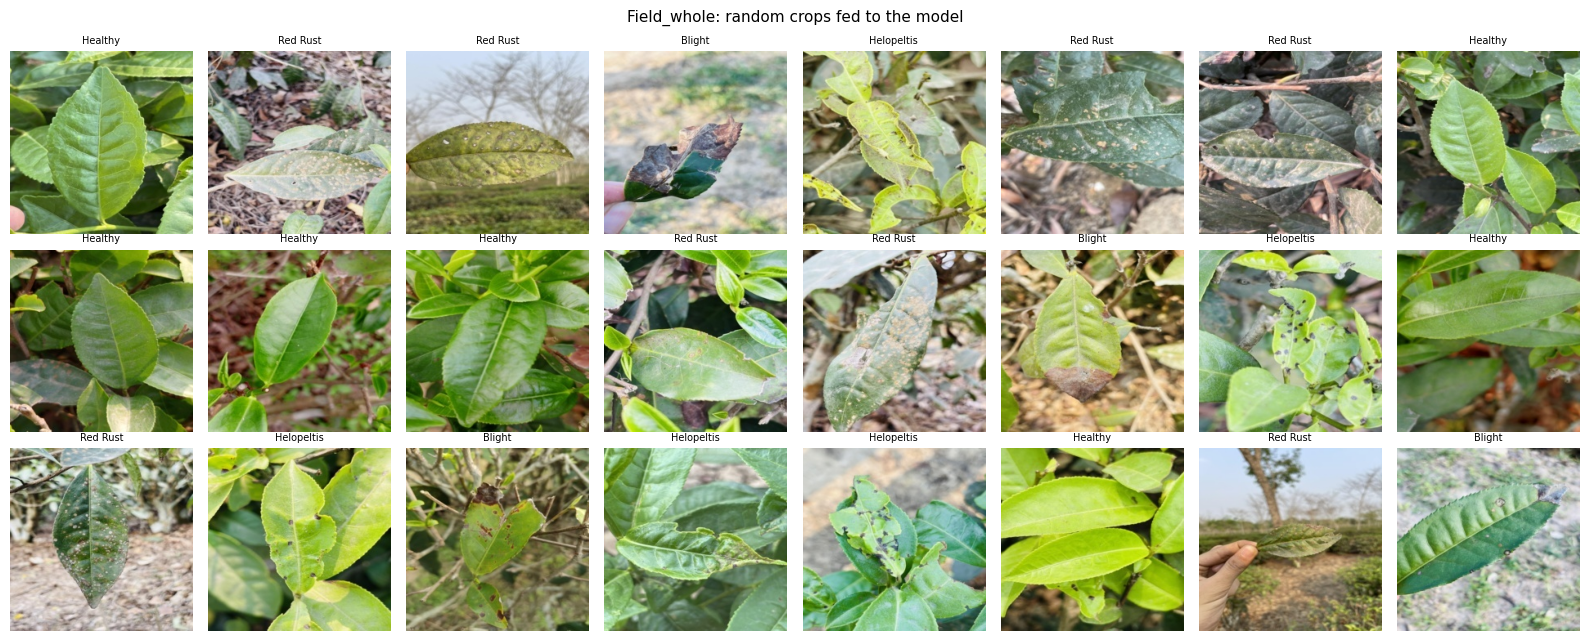

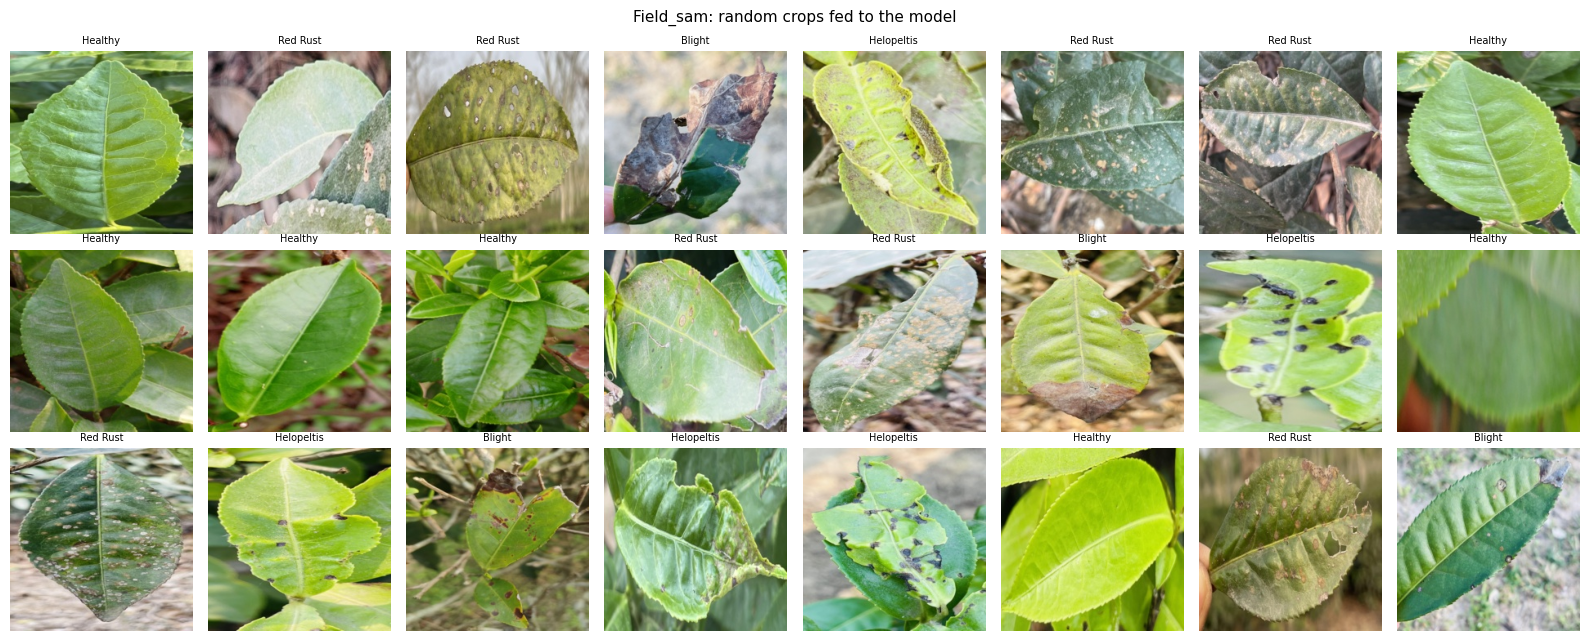

Check: one leaf per crop? (EWU boxes must be LEAF boxes, not lesion boxes.) For Ally_otsu, does the crop isolate the leaf or return the whole frame?


In [9]:
# CELL 8 — CONTACT SHEETS: inspect before trusting numbers
import matplotlib.pyplot as plt
for tag, S in SETS.items():
    k = min(24, len(S['crops'])); pick = np.random.default_rng(1).choice(len(S['crops']), k, replace=False)
    fig, ax = plt.subplots(3, 8, figsize=(16, 6.5))
    for a, i in zip(ax.ravel(), list(pick) + [None] * (24 - k)):
        a.axis('off')
        if i is not None: a.imshow(S['crops'][i]); a.set_title(S['cls'][i][:14], fontsize=7)
    fig.suptitle(f'{tag}: random crops fed to the model', fontsize=11); plt.tight_layout()
    plt.savefig(f'{OUT}/contact_{tag}.png', dpi=110); plt.show()
print('Check: one leaf per crop? (EWU boxes must be LEAF boxes, not lesion boxes.) '
      'For Ally_otsu, does the crop isolate the leaf or return the whole frame?')


In [10]:
# CELL 9 — leakage check: nearest TeaLeafDiseaseBD feature for every external crop
TEA = np.concatenate([Xtr, Xte])
for tag, S in SETS.items():
    nn = np.concatenate([(S['X'][i:i + 512] @ TEA.T).max(1) for i in range(0, len(S['X']), 512)])
    S['nn'] = nn
    print('%-11s max cosine to TeaLeafDiseaseBD: median %.3f | >=0.98: %d crops | >=0.95: %d'
          % (tag, np.median(nn), (nn >= 0.98).sum(), (nn >= 0.95).sum()))
print('Any crops >= 0.98 are candidate overlaps with your own data: inspect them and exclude if identical.')


Field_whole max cosine to TeaLeafDiseaseBD: median 0.579 | >=0.98: 0 crops | >=0.95: 0
Field_sam   max cosine to TeaLeafDiseaseBD: median 0.633 | >=0.98: 0 crops | >=0.95: 0
Any crops >= 0.98 are candidate overlaps with your own data: inspect them and exclude if identical.


In [11]:
# CELL 10 — evaluate the frozen probe (threshold fixed in-distribution)
def evaluate(score_fn, S, thr_list):
    res = {'auc': [], 'sens': [], 'spec': [], 'per_class_flag_rate': {}}
    per = {c: [] for c in np.unique(S['cls'])}
    for rep in range(N_REP):
        s = score_fn(rep, S); flag = s >= thr_list[rep]
        res['auc'].append(roc_auc_score(S['y'], s) if len(np.unique(S['y'])) == 2 else float('nan'))
        res['sens'].append(flag[S['y'] == 1].mean()); res['spec'].append((~flag)[S['y'] == 0].mean())
        for c in per: per[c].append(flag[S['cls'] == c].mean())
    summ = lambda a: (float(np.nanmean(a)), float(np.nanstd(a, ddof=1)))
    out = {k: summ(v) for k, v in res.items() if k != 'per_class_flag_rate'}
    out['per_class_flag_rate'] = {c: summ(v) for c, v in per.items()}
    out['n'] = int(len(S['y'])); out['n_healthy'] = int((S['y'] == 0).sum())
    return out

probe_score = lambda rep, S: 1 - PROBES[rep].predict_proba(S['X'])[:, HEALTHY_IDX]
ID = dict(X=Xte, y=dte, cls=np.array(['ID'] * len(dte)))
RESULTS = {'in_distribution_probe': evaluate(probe_score, ID, THR)}
for tag, S in SETS.items():
    RESULTS[f'{tag}_probe'] = evaluate(probe_score, S, THR)

def show(name, r):
    print('%-22s n=%5d  AUC %.3f±%.3f  sens %.3f±%.3f  spec %.3f±%.3f'
          % (name, r['n'], *r['auc'], *r['sens'], *r['spec']))
    for c, (m, s) in r['per_class_flag_rate'].items():
        if c != 'ID': print('      flagged as diseased  %-18s %.3f ± %.3f' % (c, m, s))
for k, r in RESULTS.items(): show(k, r)


in_distribution_probe  n= 3929  AUC 0.985±0.004  sens 0.950±0.000  spec 0.923±0.023
Field_whole_probe      n= 2500  AUC 0.962±0.017  sens 0.974±0.012  spec 0.604±0.154
      flagged as diseased  Blight             0.988 ± 0.010
      flagged as diseased  Healthy            0.396 ± 0.154
      flagged as diseased  Helopeltis         0.982 ± 0.015
      flagged as diseased  Red Rust           0.954 ± 0.013
Field_sam_probe        n= 2500  AUC 0.970±0.013  sens 0.970±0.016  spec 0.764±0.144
      flagged as diseased  Blight             0.986 ± 0.014
      flagged as diseased  Healthy            0.236 ± 0.144
      flagged as diseased  Helopeltis         0.973 ± 0.021
      flagged as diseased  Red Rust           0.955 ± 0.015


In [12]:
# CELL 11 — 4-class zero-shot identification (probe; argmax over Brown/Gray Blight, Healthy, Helopeltis, Red Rust; Brown or Gray -> Blight)
from sklearn.metrics import confusion_matrix
FOUR = {}
for tag, S in SETS.items():
    yt = np.array([CLS4.index(c) for c in S['cls']]); accs, recs, cms = [], [], []
    for m in PROBES:
        P = m.predict_proba(S['X']); P4 = np.stack([P[:, MAP4[c]].max(1) for c in CLS4], 1)   # most likely of the 5 relevant classes, then merge (summing would favour Blight)
        yp = P4.argmax(1); accs.append((yp == yt).mean())
        cm = confusion_matrix(yt, yp, labels=range(4)); cms.append(cm / cm.sum(1, keepdims=True))
        recs.append(np.diag(cms[-1]))
    recs = np.array(recs); cm_mean = np.mean(cms, 0)
    FOUR[tag] = dict(acc=(float(np.mean(accs)), float(np.std(accs, ddof=1))),
                     recall={c: (float(recs[:, i].mean()), float(recs[:, i].std(ddof=1))) for i, c in enumerate(CLS4)},
                     confusion_rows_true_cols_pred=cm_mean.round(3).tolist(), classes=CLS4)
    print('%-12s 4-class accuracy %.3f ± %.3f (chance 0.25) | recall %s' % (tag, *FOUR[tag]['acc'],
          {c: round(v[0], 2) for c, v in FOUR[tag]['recall'].items()}))
RESULTS['four_class_zero_shot'] = FOUR


Field_whole  4-class accuracy 0.624 ± 0.021 (chance 0.25) | recall {'Blight': 0.7, 'Healthy': 0.92, 'Helopeltis': 0.82, 'Red Rust': 0.04}
Field_sam    4-class accuracy 0.651 ± 0.013 (chance 0.25) | recall {'Blight': 0.77, 'Healthy': 0.95, 'Helopeltis': 0.84, 'Red Rust': 0.02}


In [13]:
# CELL 12 — deployed student tea_screener.onnx (dynamic batch), verified against its export report
import onnxruntime as ort
REP_ = json.load(open(ONNX_REPORT))
sha = hashlib.sha256(open(ONNX_PATH, 'rb').read()).hexdigest()
assert sha == REP_['sha256'], 'tea_screener.onnx is not the file described in export_report.json'
sess = ort.InferenceSession(ONNX_PATH, providers=['CPUExecutionProvider'])
iname = sess.get_inputs()[0].name
def onnx_scores(pils, bs=64):
    out = []
    for i in range(0, len(pils), bs):
        x = np.stack([TO_T(p).numpy() for p in pils[i:i + bs]]).astype(np.float32)
        z = sess.run(None, {iname: x})[0]; z = np.exp(z - z.max(1, keepdims=True)); out.append(z[:, 1] / z.sum(1))
    return np.concatenate(out)

# in-distribution scores: saved at export time (same crops, same order as _split.json)
s_id = np.load(ONNX_ID_SCORES); assert len(s_id) == len(dte)
a_id = roc_auc_score(dte, s_id)
print('deployed model: sha256 OK | test AUC %.4f (export report %.4f)' % (a_id, REP_['test_auc']))
assert abs(a_id - REP_['test_auc']) < 1e-4
# spot-check that THIS notebook's preprocessing gives the same scores on 64 test images
chk = np.random.default_rng(3).choice(len(TEST_PATHS), 64, replace=False)
s_chk = onnx_scores([otsu_crop(load_rgb(local(TEST_PATHS[i])))[0] for i in chk])
print('spot-check vs saved scores: median |diff| %.4f, max %.4f' % (np.median(np.abs(s_chk - s_id[chk])), np.abs(s_chk - s_id[chk]).max()))

thr_s = float(np.sort(s_id[dte == 1])[int(np.floor((1 - TARGET_SENS) * (dte == 1).sum()))])
fl = s_id >= thr_s
RESULTS['in_distribution_onnx_student'] = dict(auc=(float(a_id), 0.0), sens=(float(fl[dte == 1].mean()), 0.0),
                                               spec=(float((~fl)[dte == 0].mean()), 0.0), n=int(len(dte)),
                                               n_healthy=int((dte == 0).sum()), threshold=thr_s)
show('in_distribution_onnx', RESULTS['in_distribution_onnx_student'] | {'per_class_flag_rate': {}})
for tag, S in SETS.items():
    S['onnx'] = onnx_scores(S['crops'])
    RESULTS[f'{tag}_onnx_student'] = evaluate(lambda rep, S: S['onnx'], S, [thr_s] * N_REP)
    show(f'{tag}_onnx_student', RESULTS[f'{tag}_onnx_student'])
RESULTS['_onnx'] = dict(sha256=sha, export_rep=REP_['export_rep'], threshold_95sens=thr_s)
print('Note: ONNX rows are one model, so their ± is 0 by construction.')


deployed model: sha256 OK | test AUC 0.9860 (export report 0.9860)
spot-check vs saved scores: median |diff| 0.0000, max 0.0000
in_distribution_onnx   n= 3929  AUC 0.986±0.000  sens 0.950±0.000  spec 0.940±0.000
Field_whole_onnx_student n= 2500  AUC 0.639±0.000  sens 0.973±0.000  spec 0.080±0.000
      flagged as diseased  Blight             0.948 ± 0.000
      flagged as diseased  Healthy            0.920 ± 0.000
      flagged as diseased  Helopeltis         0.996 ± 0.000
      flagged as diseased  Red Rust           0.971 ± 0.000
Field_sam_onnx_student n= 2500  AUC 0.831±0.000  sens 0.976±0.000  spec 0.345±0.000
      flagged as diseased  Blight             0.960 ± 0.000
      flagged as diseased  Healthy            0.655 ± 0.000
      flagged as diseased  Helopeltis         0.997 ± 0.000
      flagged as diseased  Red Rust           0.968 ± 0.000
Note: ONNX rows are one model, so their ± is 0 by construction.


In [14]:
# CELL 13 — label-free threshold: tau = quantile of target scores at the target healthy prevalence
# (the same rule the pseudo-labelling uses; needs only an estimate of prevalence, no labels)
def ss(s, y, t):
    f = s >= t; return float(f[y == 1].mean()), float((~f)[y == 0].mean())
LABEL_FREE = {}
for tag, S in SETS.items():
    pi = float((S['y'] == 0).mean()); row = {'pi': pi}
    for dpi, name in ((0, 'true_pi'), (-0.10, 'pi_minus_10'), (0.10, 'pi_plus_10')):
        p = pi + dpi
        pr = [ss(probe_score(r, S), S['y'], np.quantile(probe_score(r, S), p)) for r in range(N_REP)]
        on = ss(S['onnx'], S['y'], np.quantile(S['onnx'], p))
        row[name] = dict(pi_used=p, probe_sens=float(np.mean([x[0] for x in pr])), probe_spec=float(np.mean([x[1] for x in pr])),
                         onnx_sens=on[0], onnx_spec=on[1])
    LABEL_FREE[tag] = row
    t = row['true_pi']
    print('%-11s pi=%.3f | probe sens %.3f spec %.3f | deployed sens %.3f spec %.3f'
          % (tag, pi, t['probe_sens'], t['probe_spec'], t['onnx_sens'], t['onnx_spec']))
RESULTS['label_free_threshold'] = LABEL_FREE


Field_whole pi=0.260 | probe sens 0.943 spec 0.837 | deployed sens 0.794 spec 0.412
Field_sam   pi=0.260 | probe sens 0.953 spec 0.865 | deployed sens 0.870 spec 0.628


In [15]:
# CELL 14 — local recalibration of the probe (1/2/5/10 labels per TARGET class), near-duplicates held out
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
def spec_at_sens(s, y):
    pos = np.sort(s[y == 1]); t = pos[int(np.floor((1 - TARGET_SENS) * len(pos)))]; return float((s < t)[y == 0].mean())
RECAL = {}
for tag in SETS:
    S = SETS[tag]; X, y, cls = S['X'], S['y'], S['cls']
    sim = X @ X.T; np.fill_diagonal(sim, -1); nn_ = sim.max(1)
    grp = connected_components(csr_matrix(X @ X.T >= DUP), directed=False)[1]
    classes_t = np.unique(cls); K = len(classes_t); cid = np.searchsorted(classes_t, cls)
    hk = int(np.where(classes_t == next(c for c in classes_t if is_healthy(c)))[0][0])
    info = dict(within_set_dup_frac=float((nn_ >= DUP).mean()), n_groups=int(grp.max() + 1),
                largest_group=int(np.bincount(grp).max()),
                healthy_in_one_group=float(np.bincount(grp[y == 0]).max() / max(1, (y == 0).sum())))
    curve = {}
    for n in (1, 2, 5, 10, 20):
        a, sp = [], []
        for rep in range(RECAL_DRAWS):
            g = np.random.default_rng(7000 + 100 * n + rep)
            lab = np.concatenate([g.choice(np.where(cid == k)[0], n, replace=False) for k in range(K)])
            te = np.where(~np.isin(grp, grp[lab]))[0]
            if len(np.unique(y[te])) < 2: continue
            m = LogisticRegression(C=1.0, max_iter=2000).fit(X[lab], cid[lab])
            s = 1 - m.predict_proba(X[te])[:, list(m.classes_).index(hk)]
            a.append(roc_auc_score(y[te], s)); sp.append(spec_at_sens(s, y[te]))
        curve[n] = dict(labels=n * K, expert_min=n * K * 8 / 60,
                        auc=(float(np.mean(a)), float(np.std(a, ddof=1))) if len(a) > 1 else None,
                        oracle_spec_at_95sens=(float(np.mean(sp)), float(np.std(sp, ddof=1))) if len(sp) > 1 else None)
    RECAL[tag] = dict(dup=info, curve=curve)
    print('%-11s within-set near-duplicates %.1f%% | groups %d | largest %d | healthy in largest group %.0f%%'
          % (tag, 100 * info['within_set_dup_frac'], info['n_groups'], info['largest_group'], 100 * info['healthy_in_one_group']))
    for n, c in curve.items():
        print('    %2d/class (%3d labels, %.1f min): AUC %s' % (n, c['labels'], c['expert_min'],
              '%.3f ± %.3f' % c['auc'] if c['auc'] else 'n/a (test set collapses after group removal)'))
    if info['within_set_dup_frac'] > 0.5:
        print('    WARNING: >50%% of %s has a near-duplicate; held-out recalibration there is not independent — do not report it' % tag)
RESULTS['recalibration'] = RECAL


Field_whole within-set near-duplicates 58.6% | groups 1679 | largest 6 | healthy in largest group 1%
     1/class (  4 labels, 0.5 min): AUC 0.886 ± 0.100
     2/class (  8 labels, 1.1 min): AUC 0.950 ± 0.025
     5/class ( 20 labels, 2.7 min): AUC 0.974 ± 0.012
    10/class ( 40 labels, 5.3 min): AUC 0.984 ± 0.007
    20/class ( 80 labels, 10.7 min): AUC 0.989 ± 0.002
Field_sam   within-set near-duplicates 58.5% | groups 1681 | largest 6 | healthy in largest group 1%
     1/class (  4 labels, 0.5 min): AUC 0.926 ± 0.081
     2/class (  8 labels, 1.1 min): AUC 0.967 ± 0.018
     5/class ( 20 labels, 2.7 min): AUC 0.984 ± 0.008
    10/class ( 40 labels, 5.3 min): AUC 0.990 ± 0.003
    20/class ( 80 labels, 10.7 min): AUC 0.992 ± 0.001


In [16]:
# CELL 15 — summary + save
def f(v): return '%.3f ± %.3f' % tuple(v) if isinstance(v, (list, tuple)) else '%.3f' % v
print('%-30s %6s %15s %15s %15s' % ('Zero-shot, threshold fixed in-dist.', 'n', 'AUC', 'sens', 'spec'))
for k in ['in_distribution_probe', 'in_distribution_onnx_student'] + [f'{t}_{m}' for t in SETS for m in ('probe', 'onnx_student')]:
    r = RESULTS[k]; print('%-30s %6d %15s %15s %15s' % (k, r['n'], f(r['auc']), f(r['sens']), f(r['spec'])))
RESULTS['_meta'] = dict(dataset='Chowdhury & Arman 2025, doi:10.17632/3x42rbj8yv.1', target_sens=TARGET_SENS,
                        thresholds_fixed_on='TeaLeafDiseaseBD test split', sam='vit_b, centre-point prompt, area 3-90%',
                        sam_plausible_mask_rate=float(np.mean(SETS['Field_sam']['sam_ok'])),
                        median_crop_area={k: float(np.median(S['area'])) for k, S in SETS.items()}, dup_threshold=DUP)
json.dump(RESULTS, open(f'{OUT}/field_results.json', 'w'), indent=2, default=float)
print('saved ->', f'{OUT}/field_results.json   (send this + contact_Field_*.png)')


Zero-shot, threshold fixed in-dist.      n             AUC            sens            spec
in_distribution_probe            3929   0.985 ± 0.004   0.950 ± 0.000   0.923 ± 0.023
in_distribution_onnx_student     3929   0.986 ± 0.000   0.950 ± 0.000   0.940 ± 0.000
Field_whole_probe                2500   0.962 ± 0.017   0.974 ± 0.012   0.604 ± 0.154
Field_whole_onnx_student         2500   0.639 ± 0.000   0.973 ± 0.000   0.080 ± 0.000
Field_sam_probe                  2500   0.970 ± 0.013   0.970 ± 0.016   0.764 ± 0.144
Field_sam_onnx_student           2500   0.831 ± 0.000   0.976 ± 0.000   0.345 ± 0.000
saved -> /content/drive/MyDrive/TeaLeaf_DINOv2_Study/results_revision_v1/field_test/field_results.json   (send this + contact_Field_*.png)
